# ¿Cuánto esperar para que la leche UAT quede deslactosada?

**Pregunta.** Con la lactosa del análisis original y del remuestreo, los días entre los dos y la temperatura media
de Rafaela (5 días previos a la recepción y el período entre análisis), ¿se puede predecir cuántos días esperar,
según la temperatura media de la semana, para que la lactosa baje de **0,1 g/100 g**?

**Datos.** Solo Senasa (MQ no mide lactosa): leche fluida UAT con lactosa medida. Lote remuestreado = mismo lote en
más de una fecha de recepción. «< 0,03» se trata como censurado (Tobit), no como 0.

**Modelo.** Primer orden: ln L₁ = ln L₀ + c − k(T)·días, con k(T) = exp(a + b·(T − 20)). El término c recoge la
baja que aparece ya al primer día: el lote se remuestrea porque el primer valor dio alto (selección), y esa baja no
es tiempo de espera. La espera se calcula solo con k(T): días = ln(L₀ / 0,1) / k(T). Se compara con el modelo sin
desfase, sin temperatura y «sin tiempo» (la baja no depende de los días).

In [1]:
import sys
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import deslactosado_uat as D

r = D.armar(escribir=True, n_boot=1000)
p, th = r["pares"], r["ajustes"]["desfase"]["theta"]
r["resumen"]

,concepto,valor
0,muestras UAT con lactosa,1176
1,lotes con remuestreo y L0 medido,86
2,"días entre análisis (mediana, máx)","4, 8"
3,remuestreos bajo LD (censurados),10
4,Spearman ln(L1/L0) contra días,-0.37 (p 0.00048)
5,k a 20 °C (1/día),0.226 (IC 0.108 a 0.507)
6,"desfase c (ln, baja inmediata del remuestreo)",-0.73 (IC -1.14 a -0.26)
7,b: efecto de 1 °C sobre ln k,0.0283 (IC -0.0160 a 0.1118)
8,k se multiplica por cada +10 °C,1.33 (IC 0.85 a 3.06)
9,razón de verosimilitud b = 0 (p),0.105


## Validación dejando un lote afuera
Error en ln(lactosa) del remuestreo (sin los censurados) y acierto al decir si queda bajo 0,1.

In [2]:
r["metricas"].round(3)

,mae_ln,rmse_ln,acierto_bajo_umbral
pred_temp,0.659,0.901,0.686
pred_sin_temp,0.649,0.839,0.663
pred_sin_tiempo,0.659,0.778,0.686
pred_desfase,0.648,0.823,0.721


## Todas las UAT: lactosa del análisis según la temperatura de los 5 días previos
Sin remuestreo: muestra que la temperatura sí importa en el conjunto, aunque en los 86 pares no alcance a medirse.

In [3]:
r["transversal"]

,t5_rango,muestras,lactosa_mediana,% bajo umbral
0,≤ 12 °C,161,0.380,11.2
1,12 a 17 °C,330,0.345,16.1
2,17 a 22 °C,323,0.230,29.7
3,> 22 °C,362,0.150,40.9


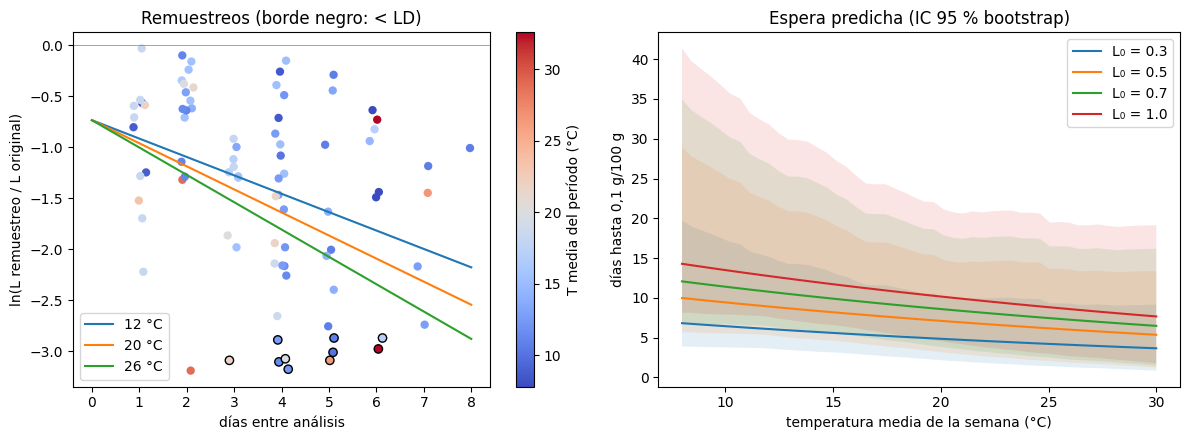

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
y = np.log(p["l1"] / p["l0"])
sc = ax[0].scatter(p["dias"] + np.random.default_rng(D.SEMILLA).uniform(-.15, .15, len(p)), y, c=p["t_exp"], cmap="coolwarm",
                   marker="o", edgecolor=np.where(p["ld1"], "k", "none"))
d = np.linspace(0, 8, 50)
for T in (12, 20, 26):
    ax[0].plot(d, th[2] - D.k_de(th, T) * d, label=f"{T} °C")
ax[0].axhline(0, color="grey", lw=.5)
ax[0].set(xlabel="días entre análisis", ylabel="ln(L remuestreo / L original)", title="Remuestreos (borde negro: < LD)")
ax[0].legend(); fig.colorbar(sc, ax=ax[0], label="T media del período (°C)")
T = np.linspace(8, 30, 50)
b = r["boot"]
for l0 in (0.3, 0.5, 0.7, 1.0):
    dd = D.dias_hasta(l0, T[:, None], b.T)
    ax[1].plot(T, D.dias_hasta(l0, T, th), label=f"L₀ = {l0}")
    ax[1].fill_between(T, *np.percentile(dd, [2.5, 97.5], axis=1), alpha=.12)
ax[1].set(xlabel="temperatura media de la semana (°C)", ylabel="días hasta 0,1 g/100 g", title="Espera predicha (IC 95 % bootstrap)")
ax[1].legend(); plt.tight_layout(); plt.show()

## Tabla de espera
Días hasta 0,1 g/100 g según la lactosa del primer análisis y la temperatura media de la semana.

In [5]:
r["tabla"].pivot(index="lactosa_inicial", columns="t_media_semana", values="dias")

t_media_semana,10,15,20,25,30
lactosa_inicial,,,,,
0.2,4.06,3.53,3.06,2.66,2.31
0.3,6.44,5.59,4.85,4.21,3.65
0.5,9.43,8.19,7.11,6.17,5.35
0.7,11.40,9.90,8.59,7.46,6.47
1.0,13.49,11.71,10.17,8.82,7.66
1.5,15.87,13.77,11.96,10.38,9.01


In [6]:
# función para usar: días de espera para una lactosa medida y la temperatura media prevista de la semana
D.dias_hasta(0.6, 18, th).round(1)

np.float64(8.4)

## Datos usados en cada entrenamiento
Cuántos datos entran en cada ajuste de este cuaderno. La unidad es el lote remuestreado (un par: primera y última recepción),
no la muestra. No hay conjunto de prueba aparte: con tan pocos lotes se ajusta con todos y la validación deja un lote afuera por vez.

In [7]:
import datos_entrenamiento as DE

miles = lambda n: f"{int(n):,}".replace(",", ".")
muestras_uat = r["muestras"]
n_lotes = int((muestras_uat.dropna(subset=["lote_id"]).groupby("lote_id")["fecha"].nunique() > 1).sum())
n_boot, n_loo = len(r["boot"]), len(r["loo"])
n_cens = int(p["ld1"].sum())
un_lote = p.iloc[:1]
base_pares = dict(parte="VI", datos="lotes UAT remuestreados, primera y última recepción", disponibles=n_lotes, usadas=len(p),
                  motivo=f"lactosa del primer análisis bajo el límite de detección (sin punto de partida): {miles(n_lotes - len(p))}")

filas = [
    DE.fila(modelo="desfase: ln L1 = ln L0 + c − k(T)·días (con censura)", **base_pares,
            particion=f"sin partición: todos los lotes; intervalos por bootstrap de lotes ({miles(n_boot)} remuestreos)",
            nota=(f"{miles(n_cens)} de los {miles(len(p))} remuestreos están bajo el límite de detección (censurados); "
                  f"los lotes salen de {miles(len(muestras_uat))} muestras UAT de Senasa con lactosa medida (MQ no mide lactosa)")),
    DE.fila(modelo="comparación: sin desfase, sin temperatura y sin tiempo", **base_pares,
            particion="sin partición: mismos lotes que el modelo principal; se comparan por AIC"),
    DE.fila(modelo="validación dejando un lote afuera (los cuatro modelos)", **base_pares,
            entrenamiento=len(p.drop(index=un_lote.index)), prueba=len(un_lote),
            particion=f"un lote afuera por vez ({miles(n_loo)} ajustes)",
            nota="error en ln(lactosa) del remuestreo sin los censurados; entrenamiento y prueba son los de cada ajuste"),
    DE.fila(parte="VI", modelo="transversal: lactosa contra la temperatura de los 5 días previos (no es un modelo)",
            datos="muestras UAT de Senasa con lactosa medida", disponibles=len(muestras_uat), usadas=muestras_uat["t5"].notna().sum(),
            motivo=f"sin temperatura de los 5 días previos: {miles(muestras_uat['t5'].isna().sum())}",
            particion="sin partición", nota="Spearman y mediana por rango de temperatura; sin remuestreo"),
]
display(DE.guardar(filas, "prediccion_deslactosado"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,VI,desfase: ln L1 = ln L0 + c − k(T)·días (con ce...,"lotes UAT remuestreados, primera y última rece...",87,1,lactosa del primer análisis bajo el límite de ...,86,86,<NA>,<NA>,sin partición: todos los lotes; intervalos por...,10 de los 86 remuestreos están bajo el límite ...
1,VI,"comparación: sin desfase, sin temperatura y si...","lotes UAT remuestreados, primera y última rece...",87,1,lactosa del primer análisis bajo el límite de ...,86,86,<NA>,<NA>,sin partición: mismos lotes que el modelo prin...,
2,VI,validación dejando un lote afuera (los cuatro ...,"lotes UAT remuestreados, primera y última rece...",87,1,lactosa del primer análisis bajo el límite de ...,86,85,<NA>,1,un lote afuera por vez (86 ajustes),error en ln(lactosa) del remuestreo sin los ce...
3,VI,transversal: lactosa contra la temperatura de ...,muestras UAT de Senasa con lactosa medida,1176,0,sin temperatura de los 5 días previos: 0,1176,1176,<NA>,<NA>,sin partición,Spearman y mediana por rango de temperatura; s...


## Lectura
- **El tiempo sí explica la baja**: cuanto más días entre análisis, más baja la lactosa (Spearman en el resumen) y el
  modelo con desfase es el mejor por AIC.
- **La temperatura, dentro de los pares, no alcanza a medirse**: el IC de b incluye 0. Los 86 pares son pocos, casi
  todos de 2020 a 2022, con 1 a 8 días y temperaturas de exposición parecidas dentro de cada estación.
- En el conjunto de las UAT la lactosa baja claramente con la temperatura previa (tabla transversal), así que el
  efecto existe; lo que falta es poder separarlo en la cinética.
- **Factibilidad**: la tabla sirve como orden de magnitud (≈ 5 a 9 días para una lactosa de 0,5 g/100 g, entre 30 y 10 °C), con
  intervalos anchos. Para un predictor operativo hacen falta remuestreos programados (por ejemplo a 0, 3, 7 y 14 días)
  y la fecha de elaboración, que hoy figura en 1 de las muestras UAT (3 en toda la leche fluida).

In [8]:
assert len(p) == 86 and p["lote_id"].is_unique and (p["dias"] > 0).all()
assert r["muestras"].columns.tolist()[:3] == ["Identificador", "Cliente", "lote_id"]
assert r["muestras"]["Cliente"].dropna().astype(str).str.match(r"^IND-\d+$").all()
assert np.isfinite(r["boot"]).all()
print("Verificación: todo en orden.")

Verificación: todo en orden.


## La aplicación, desde el cuaderno
La celda siguiente escribe `app_prediccion.py` (dos pestañas: días de espera para deslactosar una UAT y tipo de
muestra según lo medido). La de después la abre en http://localhost:8501.

Streamlit no corre adentro de una celda: es un programa aparte, y mientras está abierto el kernel queda ocupado.
Para abrirla cambiá `ABRIR_APP = True` y ejecutá la celda; para cerrarla, interrumpí el kernel (■). También se abre
desde una terminal, en la carpeta `trabajo_senasa_mq`: `../.venv/bin/streamlit run app_prediccion.py`.

In [9]:
%%writefile app_prediccion.py
# Trabajo Senasa + MQ · aplicación Streamlit con los dos modelos predictivos
# 1) Cuántos días esperar para que una leche UAT baje de 0,1 g/100 g de lactosa (src/deslactosado_uat.py).
# 2) Tipo de muestra (familia y subtipo) a partir de lo medido (src/prediccion_tipo.py).
# Los modelos los guardan los notebooks prediccion_deslactosado.ipynb y prediccion_tipo.ipynb en resultados/modelos/.
# Para abrirla, desde la carpeta trabajo_senasa_mq:  ../.venv/bin/streamlit run app_prediccion.py
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

AQUI = Path(__file__).resolve().parent
sys.path.insert(0, str(AQUI / "src"))
import deslactosado_uat as D  # noqa: E402
import prediccion_tipo as PT  # noqa: E402

st.set_page_config(page_title="Predicciones Senasa + MQ", layout="centered")
st.title("Predicciones Senasa + MQ")
st.caption("Dos modelos ajustados en los notebooks del trabajo. Cargá los parámetros y la app devuelve el resultado.")


@st.cache_resource
def cargar(ruta):
    return joblib.load(ruta)


faltan = [p for p in (D.SALIDA_MODELO, PT.SALIDA_MODELO) if not p.exists()]
if faltan:
    st.error("Faltan modelos: " + ", ".join(p.name for p in faltan) + ". Ejecutá los notebooks prediccion_*.ipynb.")
    st.stop()

tab1, tab2 = st.tabs(["Deslactosado UAT", "Tipo de muestra"])

# ------------------------------------------------------------------ 1. deslactosado
with tab1:
    m = cargar(D.SALIDA_MODELO)
    th, boot, umbral = m["theta"], m["boot"], m["umbral"]
    st.subheader("¿Cuántos días esperar?")
    st.write(f"Modelo de primer orden ajustado con {m['n_lotes']} lotes UAT remuestreados de Senasa "
             f"({m['rango_dias'][0]} a {m['rango_dias'][1]} días entre análisis). Umbral de deslactosado: "
             f"**{umbral:.1f} g/100 g**.")
    c1, c2 = st.columns(2)
    l0 = c1.number_input("Lactosa medida (g/100 g)", 0.01, 3.0, 0.60, step=0.01, format="%.2f")
    t_sem = c2.slider("Temperatura media de la semana (°C)", 5.0, 35.0, 18.0, step=0.5)

    if l0 <= umbral:
        st.success(f"Ya está en {umbral:.1f} g/100 g o menos: no hace falta esperar.")
    else:
        dias = float(D.dias_hasta(l0, t_sem, th))
        dd = D.dias_hasta(l0, t_sem, boot.T)
        inf, sup = np.percentile(dd, [2.5, 97.5])
        k1, k2 = st.columns(2)
        k1.metric("Días de espera estimados", f"{dias:.1f}")
        k2.metric("Intervalo 95 % (bootstrap)", f"{inf:.1f} a {sup:.1f}")
        st.write(f"Tasa a esa temperatura: k = {float(D.k_de(th, t_sem)):.3f} por día "
                 f"(la lactosa baja ~{100 * (1 - np.exp(-float(D.k_de(th, t_sem)))):.0f} % por día).")
        if dias > m["rango_dias"][1]:
            st.warning(f"La espera supera los {m['rango_dias'][1]} días observados entre análisis: es una extrapolación.")
        lo, hi = m["rango_t"]
        if not lo - 2 <= t_sem <= hi + 2:
            st.warning(f"Temperatura fuera del rango observado ({lo:.0f} a {hi:.0f} °C): es una extrapolación.")

    st.info("El efecto de la temperatura dentro de los remuestreos no es significativo (el IC incluye cero): "
            "tomá el resultado como orden de magnitud, no como garantía.")

    T = np.linspace(5, 35, 61)
    fig, ax = plt.subplots(figsize=(8, 4))
    for v, col in [(0.3, "#9ecae1"), (0.5, "#4292c6"), (1.0, "#08519c")]:
        ax.plot(T, D.dias_hasta(v, T, th), color=col, lw=1, label=f"L₀ = {v}")
    if l0 > umbral:
        dT = D.dias_hasta(l0, T[:, None], boot.T)
        ax.fill_between(T, *np.percentile(dT, [2.5, 97.5], axis=1), color="#c0392b", alpha=0.15)
        ax.plot(T, D.dias_hasta(l0, T, th), color="#c0392b", lw=2, label=f"esta muestra (L₀ = {l0:.2f})")
        ax.scatter([t_sem], [D.dias_hasta(l0, t_sem, th)], s=200, marker="*", color="#c0392b", zorder=5)
    ax.axvspan(*m["rango_t"], color="grey", alpha=0.08, label="temperaturas observadas")
    ax.set(xlabel="temperatura media de la semana (°C)", ylabel=f"días hasta {umbral:.1f} g/100 g",
           title="Espera predicha según la temperatura")
    ax.legend(fontsize=8)
    st.pyplot(fig)

# ------------------------------------------------------------------ 2. tipo de muestra
with tab2:
    paq = cargar(PT.SALIDA_MODELO)
    st.subheader("¿Qué tipo de muestra es?")
    st.write("Cargá los análisis que se midieron; los que no, dejalos sin marcar (el modelo también usa *qué* "
             "análisis se pidieron). Con probabilidad menor a "
             f"{paq['umbral']:.2f} el resultado queda como «sin decidir».")

    CAMPOS = [  # (variable, etiqueta, valor por defecto, medida por defecto)
        ("humedad", "Humedad (g/100 g)", 3.5, True),
        ("grasa", "Materia grasa (g/100 g)", 26.0, True),
        ("proteinas", "Proteínas (g/100 g)", 25.0, True),
        ("cenizas", "Cenizas (g/100 g)", 6.0, False),
        ("grasa_es", "Materia grasa en extracto seco (g/100 g)", 45.0, False),
        ("cloruros", "Cloruros (NaCl g/100 g)", 1.5, False),
        ("acidez_naoh", "Acidez (ml NaOH 0,1 N / 10 g SNG)", 15.0, False),
        ("acidez_lactico", "Acidez (% ácido láctico)", 0.15, False),
        ("lactosa", "Lactosa (g/100 g)", 38.0, False),
        ("galactosa", "D-galactosa (g/100 g)", 0.1, False),
        ("azucares", "Azúcares totales (g/100 g)", 50.0, False),
        ("ph", "pH", 6.6, False),
        ("aw", "Actividad de agua", 0.85, False),
        ("almidon", "Almidón total (g/100 g)", 1.0, False),
        ("sodio", "Sodio (mg/100 g)", 400.0, False),
        ("calcio", "Calcio (mg/100 g)", 900.0, False),
        ("brix", "Grado Brix (°Bx)", 70.0, False),
        ("solubilidad", "Solubilidad (%)", 99.0, False),
    ]
    valores = {}
    c1, c2 = st.columns(2)
    for i, (var, etiqueta, defecto, medido) in enumerate(CAMPOS):
        col = c1 if i % 2 == 0 else c2
        if col.checkbox(etiqueta, value=medido, key=f"chk_{var}"):
            valores[var] = col.number_input(etiqueta, value=float(defecto), key=f"val_{var}", label_visibility="collapsed")

    if not valores:
        st.warning("Marcá al menos un análisis.")
        st.stop()

    fila = {v: np.nan for v in PT.VARIABLES}
    fila.update(valores)
    n_medidos = len(valores)
    if np.isfinite(fila["humedad"]):                         # igual que en el entrenamiento
        fila["solidos"] = 100 - fila["humedad"]
    fila["n_analisis"] = n_medidos
    for v in PT.VARIABLES:
        fila[f"pide_{v}"] = int(np.isfinite(fila[v]))
    X = pd.DataFrame([fila])[paq["columnas"]]
    if np.isfinite(fila["humedad"]) and not 0 <= fila["humedad"] <= 100:
        st.error("La humedad tiene que estar entre 0 y 100.")
        st.stop()

    res = PT.predecir(paq, X).iloc[0]
    k1, k2 = st.columns(2)
    k1.metric("Familia", res["familia_pred"], f"prob. {res['prob_familia']:.2f}", delta_color="off")
    if pd.notna(res["subtipo_pred"]):
        k2.metric("Subtipo", res["subtipo_pred"], f"prob. {res['prob_subtipo']:.2f}", delta_color="off")
    if res["decision"] == "sin decidir":
        st.warning("Probabilidad baja: el modelo no decide. Mirá las alternativas abajo o agregá análisis.")
    else:
        st.success("Propuesta del modelo con probabilidad suficiente.")

    mf = paq["modelos"]["familia"]
    pf = pd.Series(mf.predict_proba(X)[0], index=mf.classes_).sort_values(ascending=True).tail(6)
    fig2, ax2 = plt.subplots(figsize=(8, 3.5))
    ax2.barh(pf.index, pf.values, color=["#c0392b" if i == res["familia_pred"] else "#4292c6" for i in pf.index])
    ax2.axvline(paq["umbral"], color="black", lw=0.8, ls="--", label=f"umbral {paq['umbral']:.2f}")
    ax2.set(xlim=(0, 1), xlabel="probabilidad", title="Familias más probables")
    ax2.legend(fontsize=8, loc="lower right")
    st.pyplot(fig2)

    if res["familia_pred"] in paq["modelos"]:
        ms = paq["modelos"][res["familia_pred"]]
        ps = pd.Series(ms.predict_proba(X)[0], index=ms.classes_).sort_values(ascending=False)
        st.write("Subtipos dentro de la familia: " + " · ".join(f"{k} {v:.2f}" for k, v in ps.items()))

    st.caption("Validación agrupada por envío: familia 81 % de acierto en general, 95 % cuando la probabilidad es ≥ 0,80.")
    with st.expander("Ver la fila que recibe el modelo"):
        st.dataframe(X.T.rename(columns={0: "valor"}))

Overwriting app_prediccion.py


In [10]:
import sys
ABRIR_APP = False   # True para abrirla (bloquea el kernel hasta interrumpirlo)
if ABRIR_APP:
    print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
    !"{sys.executable}" -m streamlit run app_prediccion.py --server.headless true
else:
    print("App escrita en app_prediccion.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.")

App escrita en app_prediccion.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.
